# EDA

In [16]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

Data extraction from CSV

In [17]:
path=Path('EDA.ipynb').resolve().parent.parent
data=pd.read_csv(path/'data/raw_data.csv')
df=pd.DataFrame(data)

*Basic Info/inspection about data*

In [18]:
print('rows and columns in data : ',df.shape)
print('\nnumeric columns description : \n\n',df.describe())
print('\nNull values : \n\n',df.isnull().sum())
print('\nColumns / Feature in data : \n\n',df.columns.tolist())
print('\nchurn distribution : \n\n',df['churn'].value_counts())
print('\ntype of data :\n\n',df.dtypes)
print('\nduplicate values : \n\n',print(df.duplicated().sum()))

rows and columns in data :  (7043, 21)

numeric columns description : 

        seniorcitizen       tenure  monthlycharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000

Null values : 

 customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn              

# Basic operation on data (EDA)

In [22]:
print('\nAll Columns / features in Data set :\n\n',df.columns)
print('\n\nTotal Churn By gender :\n\n',df.groupby('gender')['churn'].count())
print('\n\nChurn by gender : \n\n',df.groupby('gender')['churn'].value_counts())
print('\n\nAll tenure categories : \n\n',df['tenure'].sort_values().unique())
print('\n\nchurn when techsupport :\n\n',df.groupby('techsupport')['churn'].value_counts())
print('\n\nChurn on each contract type : \n\n',df.groupby('contract')['churn'].value_counts())
print('\n\nChurn when paperbilling : \n\n',df.groupby('paperlessbilling')['churn'].value_counts())
print('\n\nchrun when each payment method \n\n',df.groupby('paymentmethod')['churn'].value_counts())




All Columns / features in Data set :

 Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges',
       'totalcharges', 'churn'],
      dtype='str')


Total Churn By gender :

 gender
Female    3488
Male      3555
Name: churn, dtype: int64


Churn by gender : 

 gender  churn
Female  No       2549
        Yes       939
Male    No       2625
        Yes       930
Name: count, dtype: int64


All tenure categories : 

 [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72]


churn when techsupport :

 techsupport          churn
No                   No       2027
                     Yes      

*here after looking at some data points and features we can tell that most of features are needed to build a predictive model*

In [20]:
# due to this two columns do not quietly related and nore much useful we are removing this two streamingmovies, streamingtv
df.drop(['streamingmovies','streamingtv'],axis=1, inplace=True)

C:\Users\deven\AppData\Local\Temp\ipykernel_11200\2561507976.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['streamingmovies','streamingtv'],axis=1, inplace=True)


*Now We are performing some EDA or Feature engineering if needed concepts to clear filter and visualize enough of required from data*
*note : we'll remove some feature at the time of training of the model*

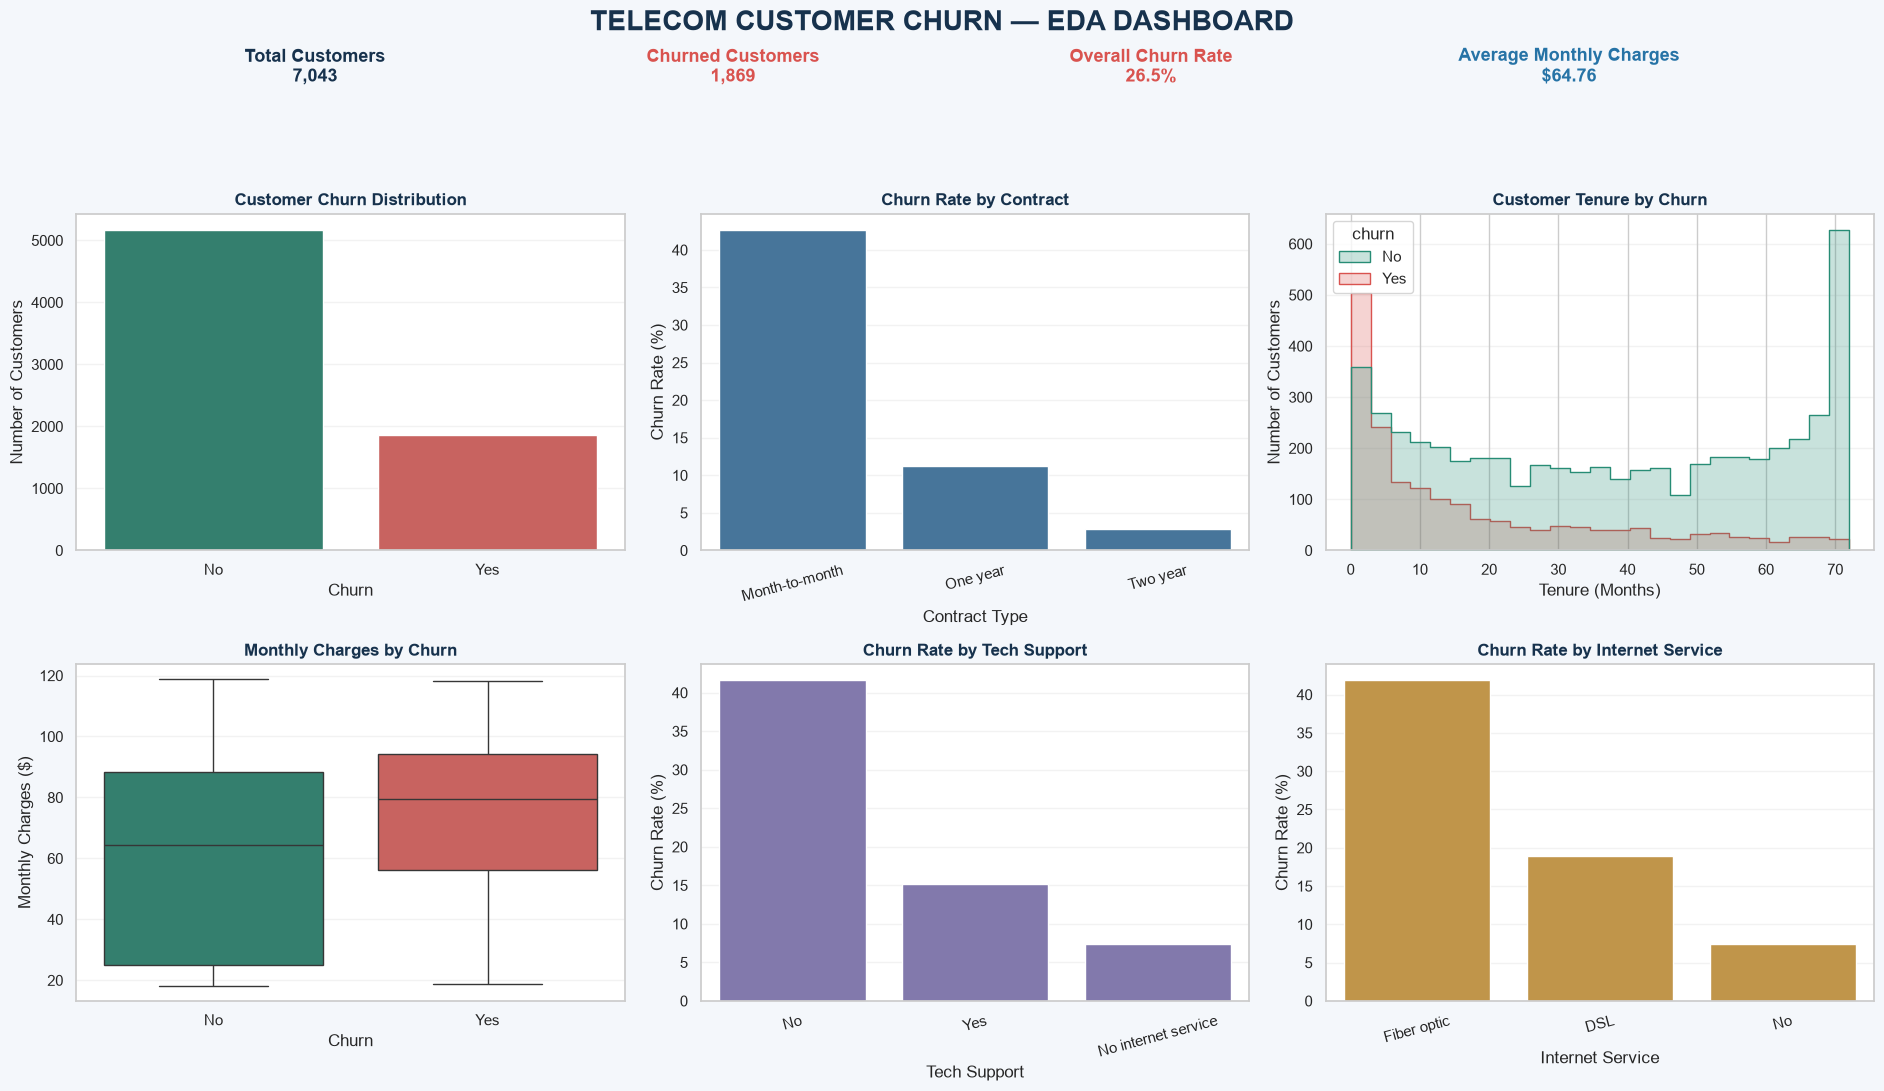

In [21]:
eda_df = df.copy()

# Clean TotalCharges for numerical analysis
eda_df["totalcharges"] = pd.to_numeric(
    eda_df["totalcharges"].astype(str).str.strip(),
    errors="coerce"
)

# Basic dashboard metrics
total_customers = len(eda_df)
churned_customers = (eda_df["churn"] == "Yes").sum()
churn_rate = churned_customers / total_customers * 100
avg_monthly_charges = eda_df["monthlycharges"].mean()

# Consistent dashboard styling
sns.set_theme(style="whitegrid", palette="deep")

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
fig.patch.set_facecolor("#F4F7FB")

fig.suptitle(
    "TELECOM CUSTOMER CHURN — EDA DASHBOARD",
    fontsize=20,
    fontweight="bold",
    color="#17324D",
    y=0.99
)

# KPI summary across the top
fig.text(
    0.17, 0.925,
    f"Total Customers\n{total_customers:,}",
    ha="center", fontsize=13, fontweight="bold",
    color="#17324D"
)

fig.text(
    0.39, 0.925,
    f"Churned Customers\n{churned_customers:,}",
    ha="center", fontsize=13, fontweight="bold",
    color="#D9534F"
)

fig.text(
    0.61, 0.925,
    f"Overall Churn Rate\n{churn_rate:.1f}%",
    ha="center", fontsize=13, fontweight="bold",
    color="#D9534F"
)

fig.text(
    0.83, 0.925,
    f"Average Monthly Charges\n${avg_monthly_charges:.2f}",
    ha="center", fontsize=13, fontweight="bold",
    color="#2673A6"
)

# 1. Overall churn distribution
churn_counts = eda_df["churn"].value_counts().reindex(
    ["No", "Yes"], fill_value=0
)

sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    hue=churn_counts.index,
    palette={"No": "#278C75", "Yes": "#D9534F"},
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Customer Churn Distribution", fontweight="bold")
axes[0, 0].set_xlabel("Churn")
axes[0, 0].set_ylabel("Number of Customers")

# 2. Churn rate by contract
contract_rate = (
    eda_df.groupby("contract")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=contract_rate.index,
    y=contract_rate.values,
    color="#3977A8",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Churn Rate by Contract", fontweight="bold")
axes[0, 1].set_xlabel("Contract Type")
axes[0, 1].set_ylabel("Churn Rate (%)")
axes[0, 1].tick_params(axis="x", rotation=15)

# 3. Tenure distribution by churn
sns.histplot(
    data=eda_df,
    x="tenure",
    hue="churn",
    bins=25,
    multiple="layer",
    element="step",
    stat="count",
    palette={"No": "#278C75", "Yes": "#D9534F"},
    ax=axes[0, 2]
)
axes[0, 2].set_title("Customer Tenure by Churn", fontweight="bold")
axes[0, 2].set_xlabel("Tenure (Months)")
axes[0, 2].set_ylabel("Number of Customers")

# 4. Monthly charges by churn status
sns.boxplot(
    data=eda_df,
    x="churn",
    y="monthlycharges",
    hue="churn",
    palette={"No": "#278C75", "Yes": "#D9534F"},
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Monthly Charges by Churn", fontweight="bold")
axes[1, 0].set_xlabel("Churn")
axes[1, 0].set_ylabel("Monthly Charges ($)")

# 5. Churn rate by tech support
support_rate = (
    eda_df.groupby("techsupport")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=support_rate.index,
    y=support_rate.values,
    color="#7D70B5",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Churn Rate by Tech Support", fontweight="bold")
axes[1, 1].set_xlabel("Tech Support")
axes[1, 1].set_ylabel("Churn Rate (%)")
axes[1, 1].tick_params(axis="x", rotation=15)

# 6. Churn rate by internet service
internet_rate = (
    eda_df.groupby("internetservice")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=internet_rate.index,
    y=internet_rate.values,
    color="#D49A36",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Churn Rate by Internet Service", fontweight="bold")
axes[1, 2].set_xlabel("Internet Service")
axes[1, 2].set_ylabel("Churn Rate (%)")
axes[1, 2].tick_params(axis="x", rotation=15)

# Final formatting
for ax in axes.flat:
    ax.set_facecolor("white")
    ax.title.set_fontsize(12)
    ax.title.set_color("#17324D")
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.savefig(path/'data'/'insights.png',dpi=500)
plt.show()
